In [ ]:
#verification du gpu
import tensorflow as tf

print("TensorFlow :", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("GPU détecté :", gpus)
else:
    print("Aucun GPU détecté. Utilisation du CPU.")

TensorFlow : 2.21.0
Aucun GPU détecté. Utilisation du CPU.


In [14]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split

DATA_DIR = "A:\DeepLearning\chapitre5\FER-2013"
TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR = os.path.join(DATA_DIR, "test")

IMG_SIZE = (48, 48)
BATCH_SIZE = 64

print("TensorFlow :", tf.__version__)
print("GPU disponibles :", tf.config.list_physical_devices("GPU"))

TensorFlow : 2.21.0
GPU disponibles : []


In [15]:
def charger_dossier(chemin, shuffle=False):
    ds = tf.keras.utils.image_dataset_from_directory(
        chemin,
        labels="inferred",
        label_mode="int",
        color_mode="grayscale",
        image_size=IMG_SIZE,
        batch_size=512,
        shuffle=shuffle,
        seed=42
    )

    class_names = ds.class_names
    images, labels = [], []

    for x, y in ds:
        images.append(x.numpy())
        labels.append(y.numpy())

    X = np.concatenate(images).astype("uint8")
    y = np.concatenate(labels)

    return X, y, class_names


x_train_original, y_train_original, class_names = charger_dossier(
    TRAIN_DIR, shuffle=False
)

x_test_original, y_test, test_classes = charger_dossier(
    TEST_DIR, shuffle=False
)

print("Classes :", class_names)
print("Train original :", x_train_original.shape)
print("Test original :", x_test_original.shape)

Found 28709 files belonging to 7 classes.
Found 7178 files belonging to 7 classes.
Classes : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Train original : (28709, 48, 48, 1)
Test original : (7178, 48, 48, 1)


In [16]:
print("Train :", x_train_original.min(), x_train_original.max())
print("Test :", x_test_original.min(), x_test_original.max())

Train : 0 255
Test : 0 255


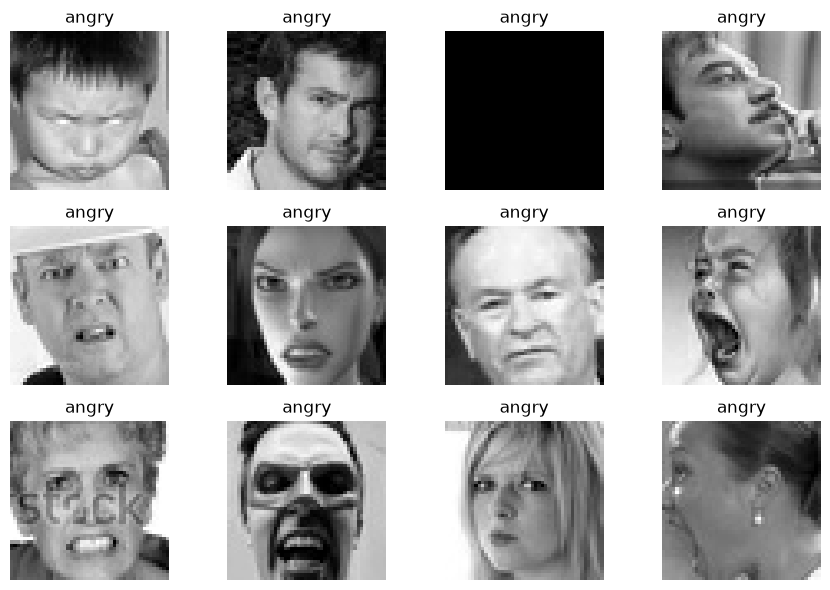

In [17]:
plt.figure(figsize=(9, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_train_original[i].squeeze(), cmap="gray")
    plt.title(class_names[y_train_original[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [18]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train_original,
    y_train_original,
    test_size=0.20,
    random_state=42,
    stratify=y_train_original
)

print("Train :", x_train.shape, y_train.shape)
print("Validation :", x_val.shape, y_val.shape)
print("Test :", x_test_original.shape, y_test.shape)

Train : (22967, 48, 48, 1) (22967,)
Validation : (5742, 48, 48, 1) (5742,)
Test : (7178, 48, 48, 1) (7178,)


In [19]:
x_train = x_train.astype("float32") / 255.0
x_val = x_val.astype("float32") / 255.0
x_test = x_test_original.astype("float32") / 255.0

print("Train :", x_train.min(), x_train.max())
print("Validation :", x_val.min(), x_val.max())
print("Test :", x_test.min(), x_test.max())

Train : 0.0 1.0
Validation : 0.0 1.0
Test : 0.0 1.0


In [20]:
assert x_train.shape[1:] == (48, 48, 1)
assert x_val.shape[1:] == (48, 48, 1)
assert x_test.shape[1:] == (48, 48, 1)

assert x_train.min() >= 0 and x_train.max() <= 1
assert x_val.min() >= 0 and x_val.max() <= 1
assert x_test.min() >= 0 and x_test.max() <= 1

print("Prétraitement terminé avec succès.")

Prétraitement terminé avec succès.


In [21]:

from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(48, 48, 1)),

    # Bloc 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Bloc 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Bloc 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(7, activation="softmax")
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,527 (2.61 MB)

 Trainable params: 683,527 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [23]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stop]
)

Epoch 1/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 29s 75ms/step - accuracy: 0.3322 - loss: 1.6793 - val_accuracy: 0.4328 - val_loss: 1.4772
Epoch 2/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 27s 75ms/step - accuracy: 0.4562 - loss: 1.4264 - val_accuracy: 0.4819 - val_loss: 1.3522
Epoch 3/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 30s 83ms/step - accuracy: 0.5098 - loss: 1.2875 - val_accuracy: 0.5188 - val_loss: 1.2748
Epoch 4/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 26s 73ms/step - accuracy: 0.5554 - loss: 1.1808 - val_accuracy: 0.5239 - val_loss: 1.2419
Epoch 5/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 27s 74ms/step - accuracy: 0.5969 - loss: 1.0873 - val_accuracy: 0.5402 - val_loss: 1.2301
Epoch 6/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 40s 71ms/step - accuracy: 0.6275 - loss: 1.0004 - val_accuracy: 0.5449 - val_loss: 1.2206
Epoch 7/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 29s 81ms/step - accuracy: 0.6656 - loss: 0.9124 - val_accuracy: 0.5554 - val_loss: 1.2279
Epoch 8/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 29s 81ms/step - accuracy: 0.6976 - loss: 0.8187 - 

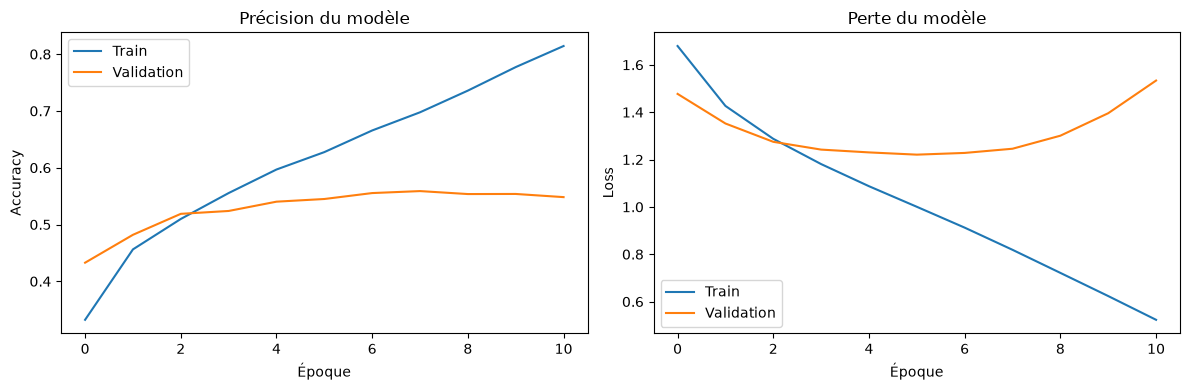

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Courbes de précision
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Précision du modèle")
plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.legend()

# Courbes de perte
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Perte du modèle")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [25]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stop]
)

Epoch 1/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 22s 62ms/step - accuracy: 0.6774 - loss: 0.8783 - val_accuracy: 0.5510 - val_loss: 1.2415
Epoch 2/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 30s 85ms/step - accuracy: 0.7010 - loss: 0.8118 - val_accuracy: 0.5559 - val_loss: 1.2661
Epoch 3/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 30s 82ms/step - accuracy: 0.7287 - loss: 0.7382 - val_accuracy: 0.5566 - val_loss: 1.3464
Epoch 4/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 30s 83ms/step - accuracy: 0.7607 - loss: 0.6558 - val_accuracy: 0.5345 - val_loss: 1.3898


In [26]:
layers.Dense(
    128,
    activation="relu",
    kernel_regularizer=keras.regularizers.l2(0.001)
),
layers.Dropout(0.5),
layers.Dense(7, activation="softmax")

<Dense name=dense_3, built=False>

In [27]:
# Conserver résultats du premier modèle
history_simple = history
model_simple = model

In [28]:

from tensorflow import keras
from tensorflow.keras import layers, regularizers

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomZoom(0.10),
], name="data_augmentation")

model_improved = keras.Sequential([
    layers.Input(shape=(48, 48, 1)),

    data_augmentation,

    # Bloc 1
    layers.Conv2D(32, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(2),
    layers.Dropout(0.20),

    # Bloc 2
    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(2),
    layers.Dropout(0.25),

    # Bloc 3
    layers.Conv2D(128, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(2),
    layers.Dropout(0.30),

    # Classification
    layers.Flatten(),
    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.BatchNormalization(),
    layers.Dropout(0.50),

    layers.Dense(7, activation="softmax")
], name="CNN_ameliore")

model_improved.summary()


Model: "CNN_ameliore"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 48, 48, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 24, 24, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 12, 12, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 684,711 (2.61 MB)

 Trainable params: 684,007 (2.61 MB)

 Non-trainable params: 704 (2.75 KB)

In [29]:
model_improved.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [30]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history_improved = model_improved.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=callbacks
)

Epoch 1/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 63s 168ms/step - accuracy: 0.2638 - loss: 2.2279 - val_accuracy: 0.3058 - val_loss: 2.0627 - learning_rate: 0.0010
Epoch 2/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 58s 161ms/step - accuracy: 0.3426 - loss: 1.8613 - val_accuracy: 0.3645 - val_loss: 1.8396 - learning_rate: 0.0010
Epoch 3/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 57s 159ms/step - accuracy: 0.3885 - loss: 1.7187 - val_accuracy: 0.4392 - val_loss: 1.5648 - learning_rate: 0.0010
Epoch 4/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 57s 159ms/step - accuracy: 0.4105 - loss: 1.6514 - val_accuracy: 0.4732 - val_loss: 1.5194 - learning_rate: 0.0010
Epoch 5/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 61s 169ms/step - accuracy: 0.4231 - loss: 1.6113 - val_accuracy: 0.4230 - val_loss: 1.5852 - learning_rate: 0.0010
Epoch 6/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.4356 - loss: 1.5864
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
359/359 ━━━━━━━━━━━━━━━━━━━━ 60s 166ms/step - accuracy: 0.435

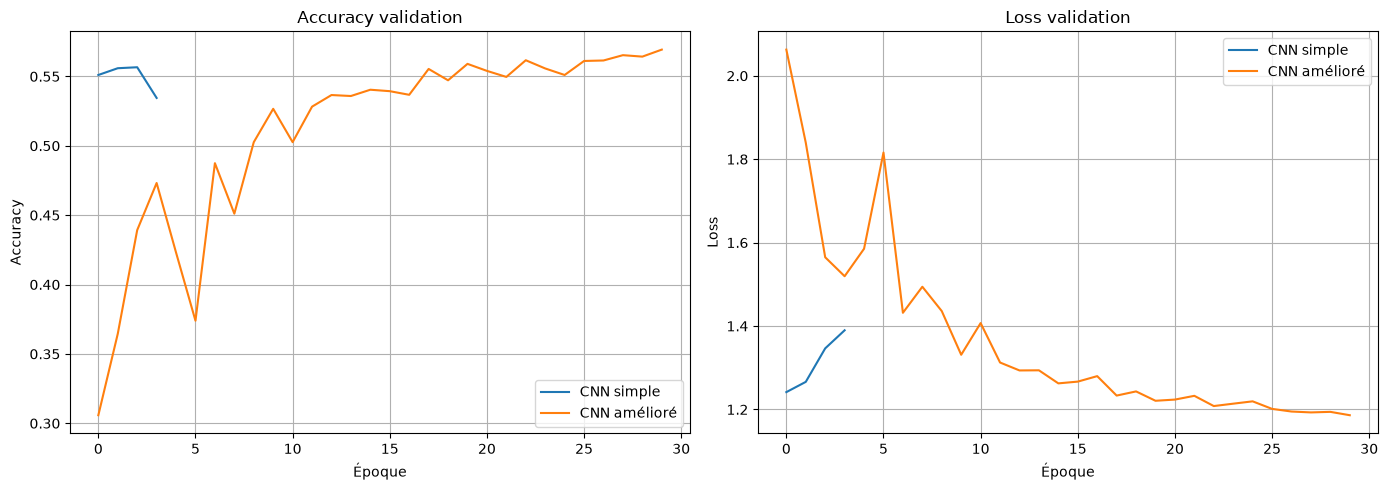

In [32]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(history_simple.history["val_accuracy"],
             label="CNN simple")
axes[0].plot(history_improved.history["val_accuracy"],
             label="CNN amélioré")
axes[0].set_title("Accuracy validation")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(history_simple.history["val_loss"],
             label="CNN simple")
axes[1].plot(history_improved.history["val_loss"],
             label="CNN amélioré")
axes[1].set_title("Loss validation")
axes[1].set_xlabel("Époque")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [34]:
import numpy as np
import pandas as pd

def resume_modele(nom, historique):
    best_epoch = np.argmin(historique.history["val_loss"])

    return {
        "Modèle": nom,
        "Meilleure époque": best_epoch + 1,
        "Accuracy train": historique.history["accuracy"][best_epoch],
        "Accuracy validation": historique.history["val_accuracy"][best_epoch],
        "Loss validation": historique.history["val_loss"][best_epoch]
    }

comparaison = pd.DataFrame([
    resume_modele("CNN simple", history_simple),
    resume_modele("CNN amélioré", history_improved)
])

display(comparaison.round(4))

,Modèle,Meilleure époque,Accuracy train,Accuracy validation,Loss validation
0,CNN simple,1,0.6774,0.5510,1.2415
1,CNN amélioré,30,0.5226,0.5693,1.1861


In [35]:
import numpy as np
import matplotlib.pyplot as plt

y_prob = model_improved.predict(x_test, batch_size=64)
y_pred = np.argmax(y_prob, axis=1)

print("Prédictions terminées.")
print("Nombre d'images test :", len(y_test))
print("Nombre de prédictions :", len(y_pred))

113/113 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step
Prédictions terminées.
Nombre d'images test : 7178
Nombre de prédictions : 7178


In [36]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    digits=3,
    zero_division=0
))

              precision    recall  f1-score   support

       angry      0.471     0.463     0.467       958
     disgust      0.632     0.108     0.185       111
        fear      0.406     0.249     0.309      1024
       happy      0.767     0.833     0.798      1774
     neutral      0.459     0.637     0.533      1233
         sad      0.465     0.393     0.426      1247
    surprise      0.667     0.721     0.693       831

    accuracy                          0.566      7178
   macro avg      0.552     0.486     0.487      7178
weighted avg      0.557     0.566     0.552      7178



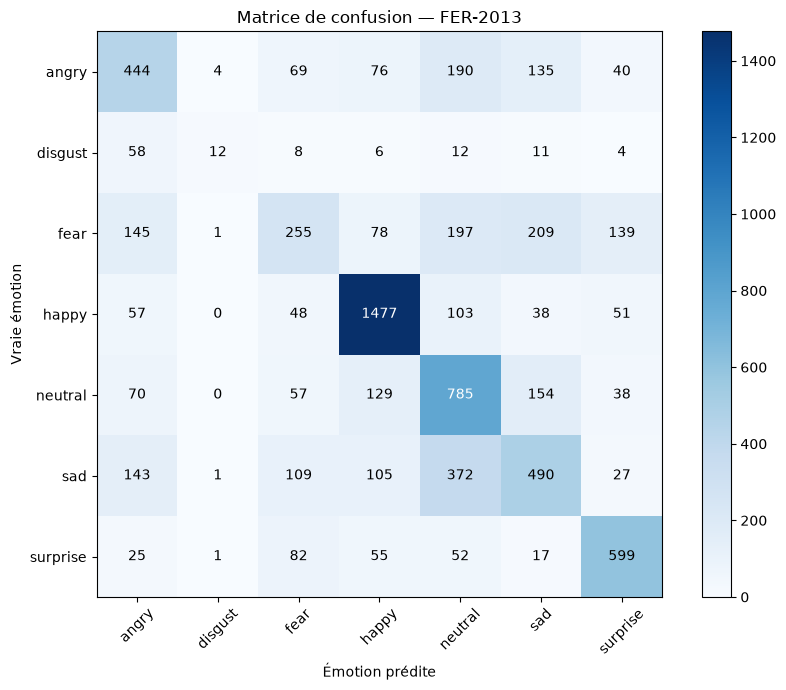

In [37]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(class_names))
)

plt.figure(figsize=(9, 7))
plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xticks(range(len(class_names)), class_names, rotation=45)
plt.yticks(range(len(class_names)), class_names)

plt.xlabel("Émotion prédite")
plt.ylabel("Vraie émotion")
plt.title("Matrice de confusion — FER-2013")

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")

plt.tight_layout()
plt.show()

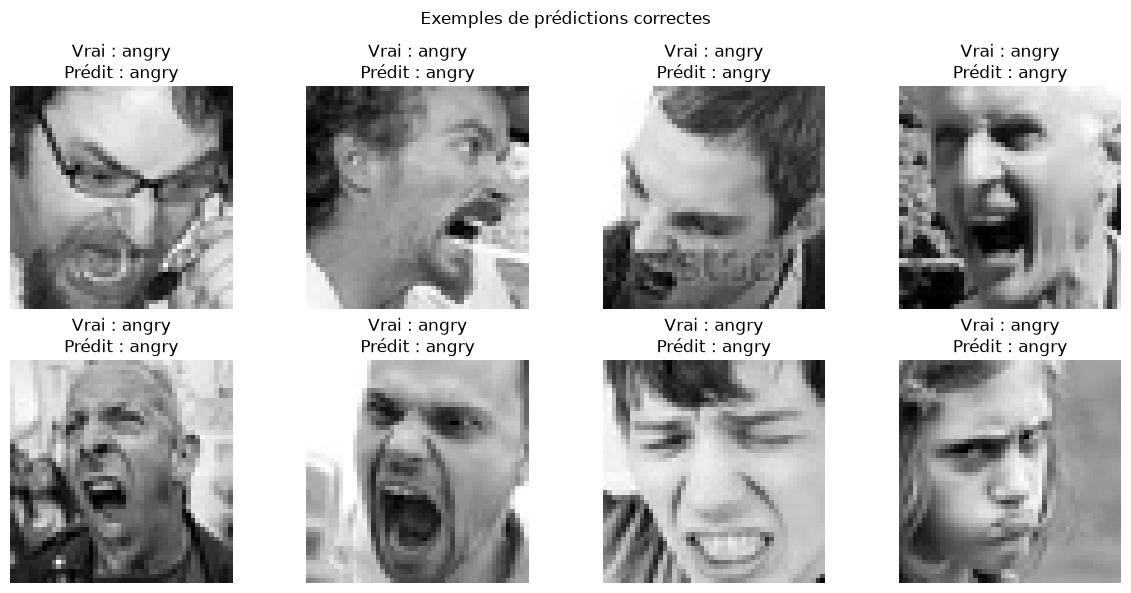

In [38]:
correct_idx = np.where(y_pred == y_test)[0]
n = min(8, len(correct_idx))

plt.figure(figsize=(12, 6))

for k, idx in enumerate(correct_idx[:n]):
    plt.subplot(2, 4, k + 1)
    plt.imshow(x_test[idx].squeeze(), cmap="gray")
    plt.title(
        f"Vrai : {class_names[y_test[idx]]}\n"
        f"Prédit : {class_names[y_pred[idx]]}"
    )
    plt.axis("off")

plt.suptitle("Exemples de prédictions correctes")
plt.tight_layout()
plt.show()

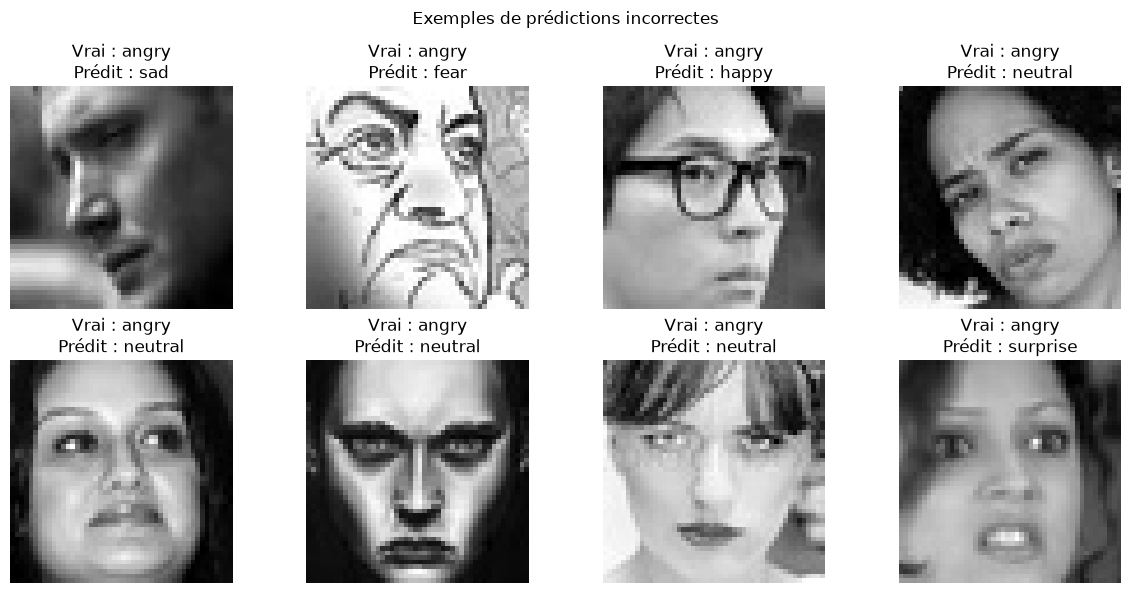

In [39]:
wrong_idx = np.where(y_pred != y_test)[0]
n = min(8, len(wrong_idx))

plt.figure(figsize=(12, 6))

for k, idx in enumerate(wrong_idx[:n]):
    plt.subplot(2, 4, k + 1)
    plt.imshow(x_test[idx].squeeze(), cmap="gray")
    plt.title(
        f"Vrai : {class_names[y_test[idx]]}\n"
        f"Prédit : {class_names[y_pred[idx]]}"
    )
    plt.axis("off")

plt.suptitle("Exemples de prédictions incorrectes")
plt.tight_layout()
plt.show()

In [40]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy test : {accuracy:.2%}")
print(f"Images correctement classées : {len(correct_idx)}")
print(f"Images mal classées : {len(wrong_idx)}")

Accuracy test : 56.59%
Images correctement classées : 4062
Images mal classées : 3116


In [42]:
print("CNN simple :")
print(np.argmin(history_simple.history["val_loss"]) + 1)
print(min(history_simple.history["val_loss"]))

print("CNN amélioré :")
print(np.argmin(history_improved.history["val_loss"]) + 1)
print(min(history_improved.history["val_loss"]))

CNN simple :
1
1.241513729095459
CNN amélioré :
30
1.186144471168518


In [44]:

import tensorflow as tf
import matplotlib.pyplot as plt

# Choisir une image test
image = x_test[0:1]

# Construire modèle intermédiaire
conv_layer = next(
    layer for layer in model_improved.layers
    if isinstance(layer, tf.keras.layers.Conv2D)
)

# Appeler le modèle pour construire son graphe
_ = model_improved(image, training=False)

feature_model = tf.keras.Model(
    inputs=model_improved.inputs,
    outputs=conv_layer.output
)

feature_maps = feature_model.predict(image)

print("Image :", image.shape)
print("Feature maps :", feature_maps.shape)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
Image : (1, 48, 48, 1)
Feature maps : (1, 48, 48, 32)


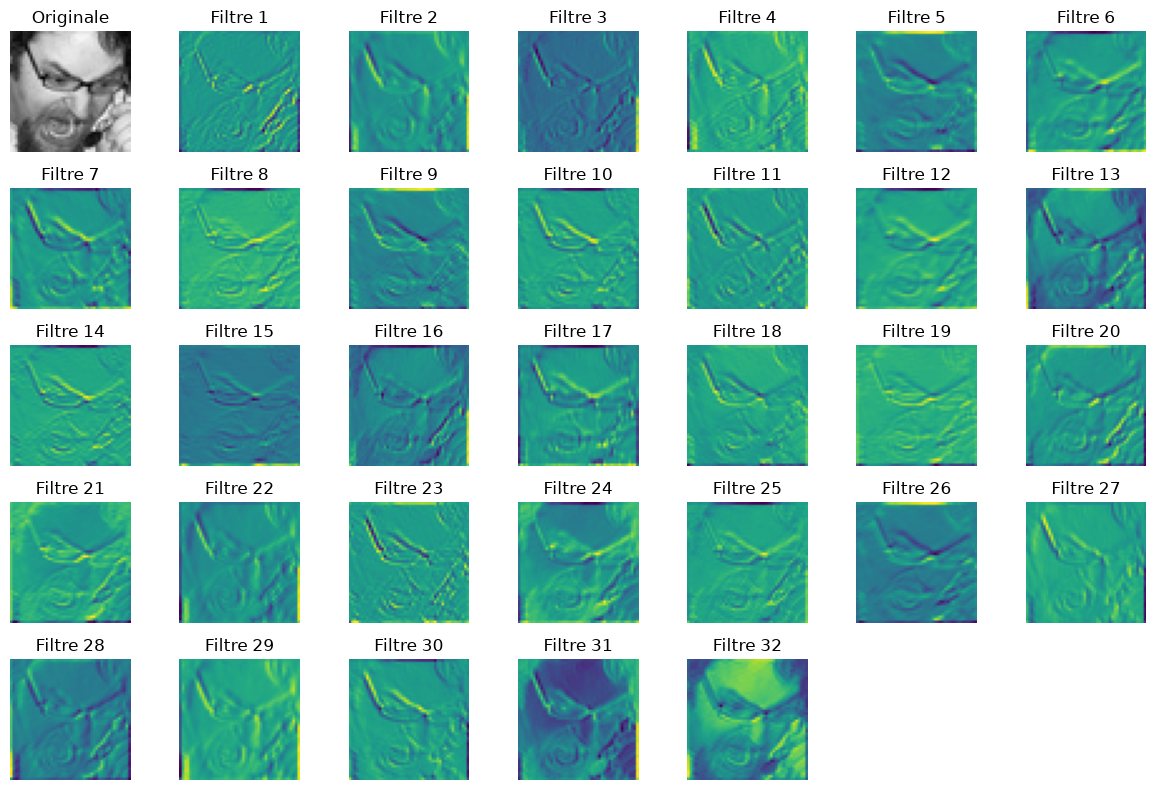

In [45]:
plt.figure(figsize=(12, 8))

# Image originale
plt.subplot(5, 7, 1)
plt.imshow(image[0].squeeze(), cmap="gray")
plt.title("Originale")
plt.axis("off")

# 32 cartes de caractéristiques
for i in range(32):
    plt.subplot(5, 7, i + 2)
    plt.imshow(feature_maps[0, :, :, i], cmap="viridis")
    plt.title(f"Filtre {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [55]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

PHOTO_PATH = r"A:\DeepLearning\ta.jpg"

# Charger en niveaux de gris
img = keras.utils.load_img(
    PHOTO_PATH,
    color_mode="grayscale",
    target_size=(48, 48)
)

# Convertir et normaliser
img_array = keras.utils.img_to_array(img).astype("float32") / 255.0

# Ajouter dimension du batch
img_array = np.expand_dims(img_array, axis=0)

print("Forme de l'image :", img_array.shape)

Forme de l'image : (1, 48, 48, 1)


In [56]:
class_names = [
    "angry", "disgust", "fear",
    "happy", "neutral", "sad", "surprise"
]

predictions = model_improved.predict(img_array, verbose=0)

predicted_index = np.argmax(predictions[0])
predicted_emotion = class_names[predicted_index]
confidence = predictions[0][predicted_index]

print("Émotion prédite :", predicted_emotion)
print(f"Score du modèle : {confidence:.2%}")

Émotion prédite : happy
Score du modèle : 30.42%


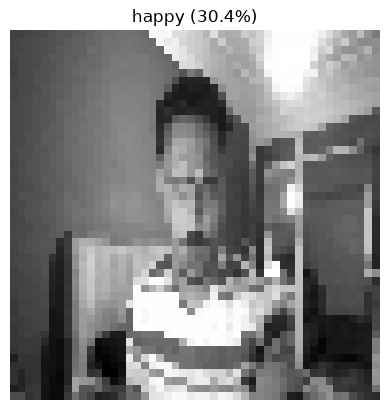

In [57]:
plt.imshow(img_array[0].squeeze(), cmap="gray")
plt.title(f"{predicted_emotion} ({confidence:.1%})")
plt.axis("off")
plt.show()

In [58]:
import json

with open("README_results.txt", "w", encoding="utf-8") as f:
    f.write("CLASSES\n")
    f.write(str(class_names) + "\n\n")

    f.write("DATASET\n")
    f.write(f"Train: {x_train.shape}\n")
    f.write(f"Validation: {x_val.shape}\n")
    f.write(f"Test: {x_test.shape}\n\n")

    f.write("CNN SIMPLE\n")
    f.write(str(history_simple.history) + "\n\n")

    f.write("CNN AMELIORE\n")
    f.write(str(history_improved.history) + "\n\n")

    f.write("MODEL SUMMARY\n")
    model_improved.summary(
        print_fn=lambda line: f.write(line + "\n")
    )

print("Fichier README_results.txt créé")

Fichier README_results.txt créé


In [59]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

test_loss, test_accuracy = model_improved.evaluate(
    x_test, y_test, verbose=0
)

y_prob = model_improved.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print(f"Test accuracy : {test_accuracy:.4f}")
print(f"Test loss : {test_loss:.4f}")

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    zero_division=0
))

print("Matrice de confusion :")
print(confusion_matrix(y_test, y_pred))

Test accuracy : 0.5659
Test loss : 1.1883
              precision    recall  f1-score   support

       angry       0.47      0.46      0.47       958
     disgust       0.63      0.11      0.18       111
        fear       0.41      0.25      0.31      1024
       happy       0.77      0.83      0.80      1774
     neutral       0.46      0.64      0.53      1233
         sad       0.46      0.39      0.43      1247
    surprise       0.67      0.72      0.69       831

    accuracy                           0.57      7178
   macro avg       0.55      0.49      0.49      7178
weighted avg       0.56      0.57      0.55      7178

Matrice de confusion :
[[ 444    4   69   76  190  135   40]
 [  58   12    8    6   12   11    4]
 [ 145    1  255   78  197  209  139]
 [  57    0   48 1477  103   38   51]
 [  70    0   57  129  785  154   38]
 [ 143    1  109  105  372  490   27]
 [  25    1   82   55   52   17  599]]
